# 05 — When is the model wrong?
Train on 0 HP only, test on 1, 2 and 3 HP. Load changes shaft speed (1797 → ~1725 rpm) and the vibration level: a small distribution shift, like a real machine running at a different operating point than the one it was trained on.

In [1]:
import sys; sys.path.insert(0, '../src')
import numpy as np, matplotlib.pyplot as plt
import bearing as b
plt.rcParams['figure.dpi'] = 110

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
Xtr, ytr, _, _ = b.dataset(loads=[0])
clf = RandomForestClassifier(n_estimators=200, random_state=0).fit(Xtr, ytr)
rows = []
for load in [1, 2, 3]:
    X, y, _, _ = b.dataset(loads=[load])
    p = clf.predict(X); conf = clf.predict_proba(X).max(1)
    rows.append((load, accuracy_score(y, p), conf[p == y].mean(), conf[p != y].mean() if (p != y).any() else np.nan))
    print(f'{load} HP  acc={rows[-1][1]:.3f}  mean confidence right={rows[-1][2]:.2f}  wrong={rows[-1][3]:.2f}')

1 HP  acc=1.000  mean confidence right=0.97  wrong=nan


2 HP  acc=1.000  mean confidence right=0.94  wrong=nan


3 HP  acc=1.000  mean confidence right=0.83  wrong=nan


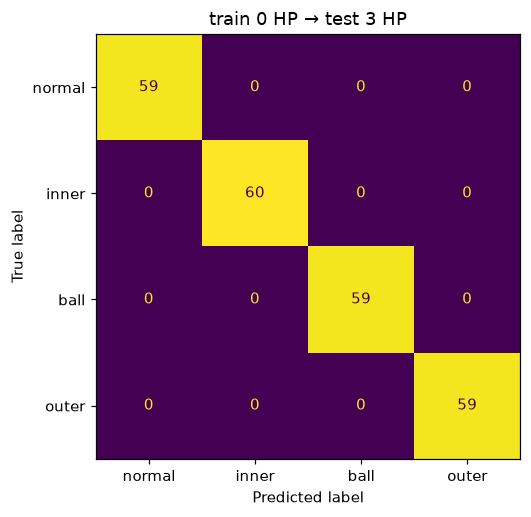

In [3]:
X3, y3, _, _ = b.dataset(loads=[3])
ConfusionMatrixDisplay.from_estimator(clf, X3, y3, labels=b.CLASSES, colorbar=False)
plt.title('train 0 HP → test 3 HP'); plt.tight_layout(); plt.savefig('../images/01-load-shift-cm.png')

In [4]:
# what if we drop the absolute-amplitude features (rms, peak, std) that depend on load?
keep = [i for i, n in enumerate(b.FEATURE_NAMES) if n not in ('rms', 'peak', 'std')]
clf2 = RandomForestClassifier(n_estimators=200, random_state=0).fit(Xtr[:, keep], ytr)
for load in [1, 2, 3]:
    X, y, _, _ = b.dataset(loads=[load])
    print(f'{load} HP  acc without amplitude features = {accuracy_score(y, clf2.predict(X[:, keep])):.3f}')

1 HP  acc without amplitude features = 1.000


2 HP  acc without amplitude features = 1.000


3 HP  acc without amplitude features = 0.996


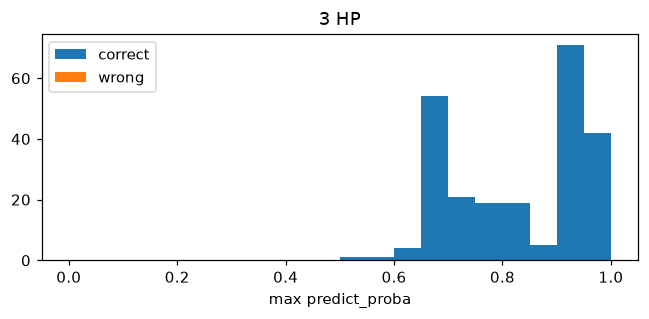

In [5]:
# confidence histogram on 3 HP: is the model confident when it is wrong?
p = clf.predict(X3); conf = clf.predict_proba(X3).max(1)
plt.figure(figsize=(6, 3))
plt.hist([conf[p == y3], conf[p != y3]], bins=20, range=(0, 1), label=['correct', 'wrong'], stacked=True)
plt.xlabel('max predict_proba'); plt.legend(); plt.title('3 HP'); plt.tight_layout()
plt.savefig('../images/01-confidence.png')

## A harder shift: bigger defects
Load change barely hurts at 0.007". Now keep 0 HP but test on **0.021"** faults (3× larger defect, never seen in training). A real bearing's defect grows over time, so this is the shift a deployed model actually meets.

0.021" accuracy = 0.565
mean confidence right=0.47  wrong=0.40


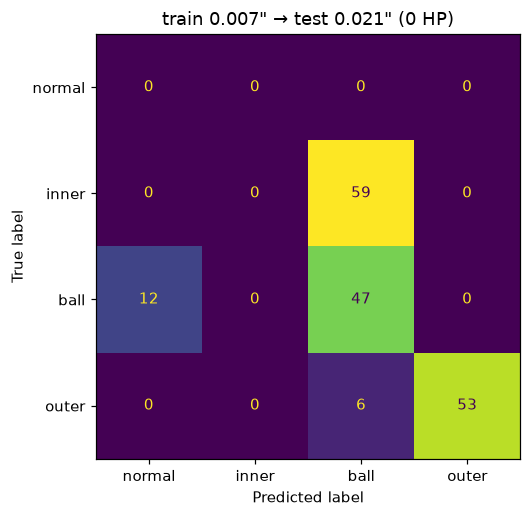

In [6]:
X21, y21, _, _ = b.dataset(loads=[0], files=b.FILES_021)
p = clf.predict(X21); conf = clf.predict_proba(X21).max(1)
print(f'0.021" accuracy = {accuracy_score(y21, p):.3f}')
print(f'mean confidence right={conf[p == y21].mean():.2f}  wrong={conf[p != y21].mean():.2f}')
ConfusionMatrixDisplay.from_predictions(y21, p, labels=b.CLASSES, colorbar=False)
plt.title('train 0.007" → test 0.021" (0 HP)'); plt.tight_layout(); plt.savefig('../images/01-fault-size-shift-cm.png')